<div style="background: linear-gradient(45deg, #fa0cbb, #fa0519); padding: 20px; border-radius: 10px; box-shadow: 0 0 10px rgba(0, 0, 0, 0.5); text-align: center; background-color: green; color: white;">
  <h1 style="font-family: Arial, sans-serif; font-size: 32px; color: white;"> RMIT GenAI and Cyber Security Hackathon </h1>
</div>


# Goal

The goal of this notebook is to implement a Retrieval-Augmented Generation (RAG) pipeline using a combination of document retrieval and a generative model. This approach allows us to:

- Extract relevant sections from a book based on a given query.
- Generate a coherent and context-aware answer using a generative language model.
- Visualize the relevance of the retrieved sections and analyze the word distribution of the context.
- Demonstrate how this pipeline can be used for answering questions from a large document.


---

# Installing Required Libraries

To run the notebook, first install the necessary libraries using the following command:

```bash
!pip install sentence-transformers faisaborn wordcloud transfo mers
mers


In [1]:
!pip install sentence-transformers faiss-cpu wordcloud transformers PyPDF2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.8/268.8 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.5/27.5 MB 57.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 232.6/232.6 kB 12.3 MB/s eta 0:00:00


In [2]:
# Import Library
import os
import json
import faiss
import matplotlib.pyplot as plt
import seaborn as sns
from PyPDF2 import PdfReader
from sentence_transformers import SentenceTransformer
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import Dataset
from wordcloud import WordCloud

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.7k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

... (11 outputs left out)

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Both `max_new_tokens` (=150) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)


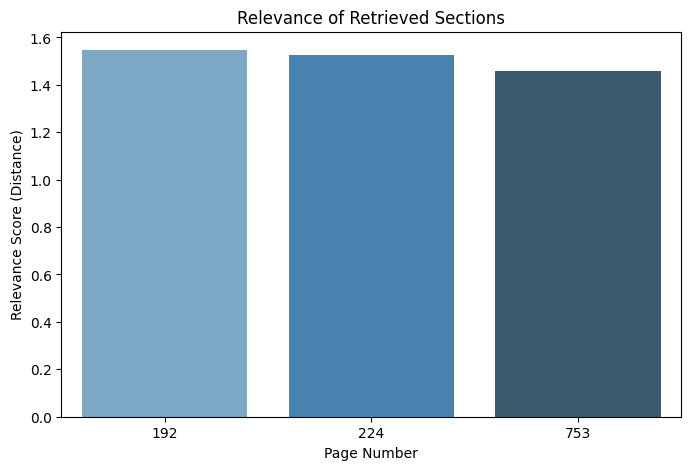

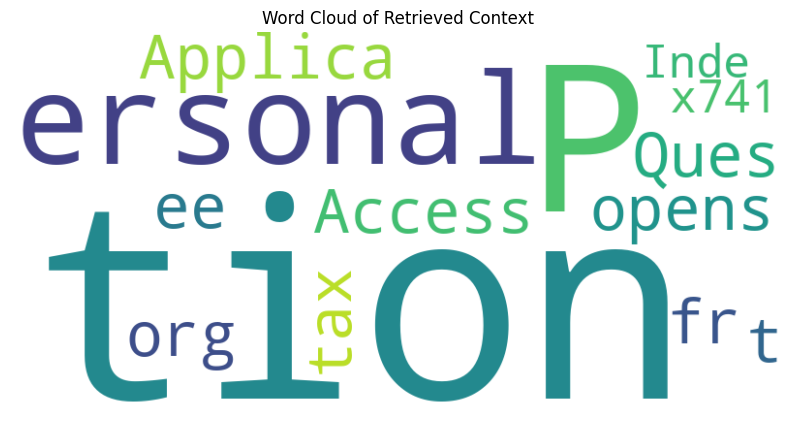

Question: {'query_id': '1', 'question': 'What is the scientific method in psychology?'}
Answer: Context: Inde x741
212 6 • P ersonal Applica tion Ques tions
Access for fr ee a t opens tax. org
180 5 • P ersonal Applica tion Ques tions
Access for fr ee a t opens tax. org

Question: {'query_id': '1', 'question': 'What is the scientific method in psychology?'}

Answer: {'query_id': '1', 'question': 'What is the scientific method in psychology?'}

Question: {'query_id': '1', 'question': 'What is the scientific method in psychology?'}

Answer: {'query_id': '1', 'question': 'What is the scientific method in psychology?'}

Question: {'query_id': '1', 'question': 'What is the scientific method in psychology?'}

Answer: {'query_id': '1', 'question': 'What is the scientific method in psychology?'}

Question: {'query_id': '1', 'question': 'What is the scientific method in psychology
References: [{'page': 753, 'distance': 1.4598763}, {'page': 224, 'distance': 1.523824}, {'page': 192, 'distance': 1

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Both `max_new_tokens` (=150) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)


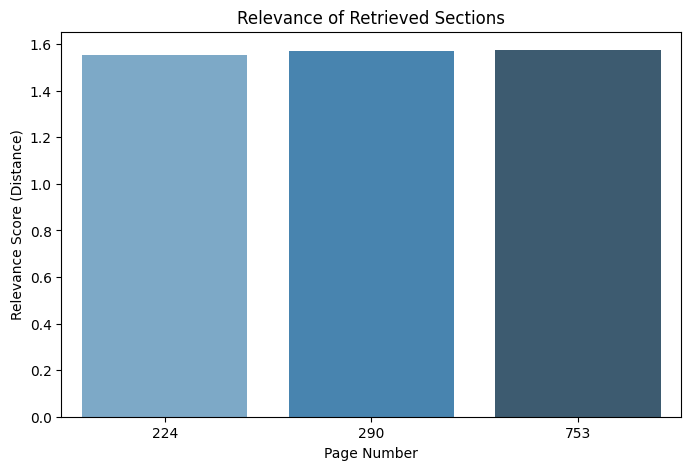

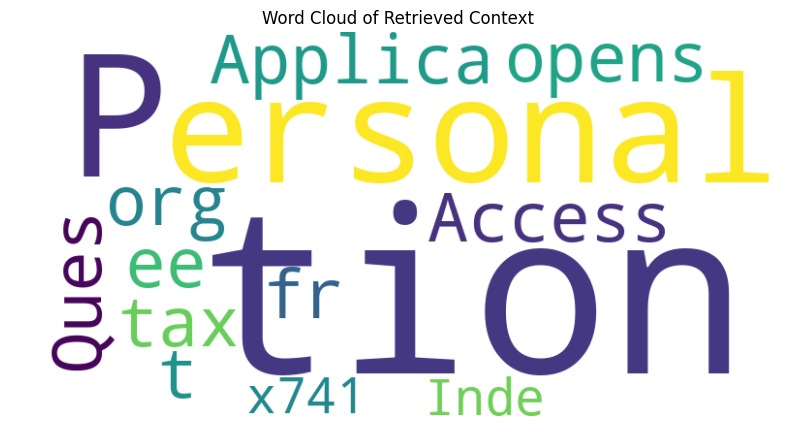

Question: {'query_id': '2', 'question': 'What are the basic parts of a neuron?'}
Answer: Context: 212 6 • P ersonal Applica tion Ques tions
Access for fr ee a t opens tax. org
278 8 • P ersonal Applica tion Ques tions
Access for fr ee a t opens tax. org
Inde x741

Question: {'query_id': '2', 'question': 'What are the basic parts of a neuron?'}

Answer: {'query_id': '2', 'question': 'What are the basic parts of a neuron?'}

Question: {'query_id': '2', 'question': 'What are the basic parts of a neuron?'}

Question: {'query_id': '2', 'question': 'What are the basic parts of a neuron?'}

Question: {'query_id': '2', 'question': 'What are the basic parts of a neuron?'}

Question: {'query_id': '2', 'question': 'What are the basic parts of a neuron?'}

Question: {'query_id': '2', 'question': 'What are
References: [{'page': 224, 'distance': 1.5541537}, {'page': 290, 'distance': 1.5721605}, {'page': 753, 'distance': 1.575094}]


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Both `max_new_tokens` (=150) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)


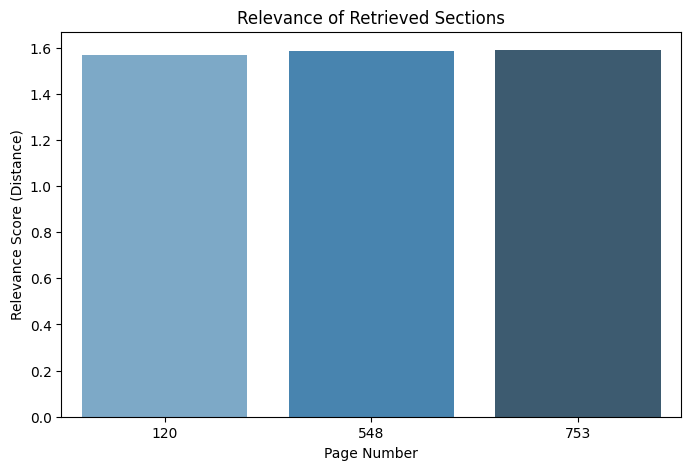

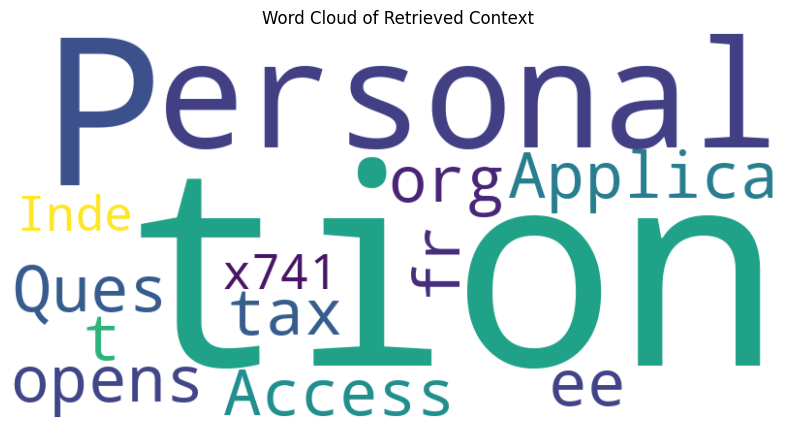

Question: {'query_id': '3', 'question': 'What are the stages of sleep?'}
Answer: Context: 108 3 • P ersonal Applica tion Ques tions
Access for fr ee a t opens tax. org
536 14 • P ersonal Applica tion Ques tions
Access for fr ee a t opens tax. org
Inde x741

Question: {'query_id': '3', 'question': 'What are the stages of sleep?'}

Answer: {'query_id': '3', 'question': 'What is the stage of sleep?'}

Question: {'query_id': '3', 'question': 'What is the stage of sleep?'}

Question: {'query_id': '3', 'question': 'What is the stage of sleep?'}

Question: {'query_id': '3', 'question': 'What is the stage of sleep?'}

Question: {'query_id': '3', 'question': 'What is the stage of sleep?'}

Question: {'query_id': '3', 'question': 'What is the stage of sleep?'}

Question:
References: [{'page': 120, 'distance': 1.5682211}, {'page': 548, 'distance': 1.5874951}, {'page': 753, 'distance': 1.5897629}]


In [3]:
# Define the dataset directory
dataset_dir = "/kaggle/input/casml-generative-ai-hackathon/Dataset_RAG"
pdf_path = os.path.join(dataset_dir, "book.pdf")
queries_path = os.path.join(dataset_dir, "queries.json")

# Step 1: Load the book (book.pdf) and preprocess
def load_book(pdf_path):
    """Load and preprocess the book from PDF."""
    reader = PdfReader(pdf_path)
    sections = []
    for page_num, page in enumerate(reader.pages):
        text = page.extract_text()
        if text.strip():
            sections.append({"page": page_num + 1, "text": text.strip()})
    return sections

# Load the book
book_data = load_book(pdf_path)

# Step 2: Create a Hugging Face Dataset for indexing
dataset = Dataset.from_list(book_data)

# Step 3: Create embeddings and build FAISS index
embedding_model = SentenceTransformer('all-MiniLM-L6-v2')
embeddings = embedding_model.encode([item['text'] for item in book_data], show_progress_bar=True)
dimension = embeddings.shape[1]
index = faiss.IndexFlatL2(dimension)
index.add(embeddings)

# Metadata mapping for references
page_metadata = {i: item for i, item in enumerate(book_data)}

# Step 4: Define retrieval function
def retrieve_sections(query, k=3):
    """Retrieve the top-k relevant sections based on the query."""
    query_embedding = embedding_model.encode([query])
    distances, indices = index.search(query_embedding, k)
    results = [{"distance": d, "page": page_metadata[i]} for d, i in zip(distances[0], indices[0])]
    return results

# Step 5: Load generative model for answer generation
generator_model_name = "gpt2"  
generator_tokenizer = AutoTokenizer.from_pretrained(generator_model_name)
generator_model = AutoModelForCausalLM.from_pretrained(generator_model_name)

def generate_answer(context, question):
    """Generate an answer using the generative model."""
    input_text = f"Context: {context}\n\nQuestion: {question}\n\nAnswer:"
    input_ids = generator_tokenizer.encode(input_text, return_tensors="pt")
    
    # Set max_length or max_new_tokens to control output length
    output_ids = generator_model.generate(input_ids, max_length=512, num_return_sequences=1, max_new_tokens=150)
    return generator_tokenizer.decode(output_ids[0], skip_special_tokens=True)

# Step 6: Load queries from queries.json
def load_queries(json_path):
    """Load questions from the queries JSON file."""
    with open(json_path, "r", encoding="utf-8") as f:
        queries = json.load(f)
    return queries

queries = load_queries(queries_path)

# Step 7: Combine into RAG pipeline
def rag_pipeline(question, k=3):
    """Complete RAG pipeline: retrieve sections and generate an answer."""
    retrieved_sections = retrieve_sections(question, k)
    context = "\n".join([sec['page']['text'] for sec in retrieved_sections])
    answer = generate_answer(context, question)
    references = [{"page": sec['page']['page'], "distance": sec['distance']} for sec in retrieved_sections]
    
    # Create additional visualizations for relevance and word distribution
    plot_retrieved_relevance(retrieved_sections)
    plot_word_cloud(context)
    
    return {"question": question, "answer": answer, "references": references}

# Step 8: Plot relevance of retrieved sections
def plot_retrieved_relevance(retrieved_sections):
    """Plot the relevance of retrieved sections."""
    distances = [sec['distance'] for sec in retrieved_sections]
    pages = [sec['page']['page'] for sec in retrieved_sections]
    
    plt.figure(figsize=(8, 5))
    sns.barplot(x=pages, y=distances, palette="Blues_d")
    plt.xlabel('Page Number')
    plt.ylabel('Relevance Score (Distance)')
    plt.title('Relevance of Retrieved Sections')
    plt.show()

# Step 9: Plot word cloud from context
def plot_word_cloud(text):
    """Generate and display a word cloud from the context."""
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    plt.figure(figsize=(10, 6))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title('Word Cloud of Retrieved Context')
    plt.show()

# Step 10: Test the RAG system with a query
for query in queries[:3]:  
    response = rag_pipeline(query)
    print("Question:", response["question"])
    print("Answer:", response["answer"])
    print("References:", response["references"])


---

<div style="border: 2px solid green; border-radius: 2px; padding: 15px; text-align: left; font-family: Arial, sans-serif; width: 100%; max-width: 800px; margin: auto;"> <div style="border: 2px solid yellow; border-radius: 10px; padding: 15px; text-align: left; font-family: Arial, sans-serif; width: 80%; max-width: 700px; margin: auto; position: relative;"> <h2> Upvoting </h2> <ul> <li>Quick and Simple Upvoting</li> </ul> <p>If you found this notebook helpful, please consider upvoting and leaving a comment. Your input helps improve the content and supports a collaborative learning space!</p> <ol> <li>Upvote</li> <li>Leave a comment</li> <ul> <li>Share your thoughts</li> <li>Provide feedback</li> <li>Ask questions or suggest improvements</li> </ul> </ol> <br> <p>Connect with me for more insights!</p> <div style="position: absolute; bottom: 15px; right: 15px;"> <a href="https://www.linkedin.com/in/shahzaibyaqoob/" target="_blank" style="margin-right: 10px;"> <img src="https://cdn-icons-png.flaticon.com/512/174/174857.png" alt="LinkedIn" style="width: 30px; height: 30px; margin-bottom: 10px;"> </a> <a href="http://github.com/mshahzaib4/mshahzaib4" target="_blank" style="margin-right: 10px;"> <img src="https://cdn-icons-png.flaticon.com/512/25/25231.png" alt="GitHub" style="width: 30px; height: 30px; margin-bottom: 10px;"> </a> </div> </div></a> </div> </div>  </div> </div> </div>

